In [5]:
import matplotlib.pyplot as plt
!pip install scipy


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.integrate as si

In [7]:
def forceIJ(Ri, Rj):
    Rij = Rj - Ri
    return Rij / (np.linalg.norm(Rij)**3 )
    
def planets(t, y):
    Rsun = [0,0]
    N=y.shape[0]//4
    Msun = 10
    RV = np.reshape( y, (2,2,N) )
    VA = RV*0
    for i in range(N):
        Ri = RV[0,:,i]
        Vi = RV[1,:,i]
        Fi = forceIJ( Ri, Rsun ) * Msun
        for j in range(N):
            if (j!=i):
                Rj = RV[0,:,j]
                Fi += forceIJ( Ri, Rj )
        VA[0,:,i] = Vi
        VA[1,:,i] = Fi
    return np.reshape( VA, (4*N ))
    

In [4]:
def manyplanets( y0, tmax ):
    N=y0.shape[2]
    y0_1D = np.reshape( y0, (4*N) )
    sol = si.solve_ivp( fun=planets, y0=y0_1D, t_span=[0, tmax], max_step=1e-3 )
    numTimes = len(sol.t)
    RV = np.reshape( sol.y, (2,2,N,numTimes) )
    plt.figure( figsize=(3,3) )
    plt.scatter( RV[0,0,0,0], RV[0,1,0,0] )
    plt.scatter( RV[0,0,1,0], RV[0,1,1,0] )
    plt.scatter( RV[0,1,1,0], RV[0,1,1,1] )
    plt.plot( RV[0,0,0,:], RV[0,1,0,:] )
    plt.plot( RV[0,0,1,:], RV[0,1,1,:] )
    plt.plot(RV[1,0,1,:], RV[0,0,1,:])
    #print(sol.y.shape)
    

In [8]:
#y0 = np.random.random( (2,2,2) ) - 0.5
y0 = np.zeros( (2,2,3) )
y0[0,0,0] = 1.0
y0[1,0,0] = 0.0
y0[0,1,0] = 0.0
y0[1,1,0] = 1.0

y0[0,0,1] = -0.9
y0[1,0,1] = 0.0
y0[0,1,1] = 0.0
y0[1,1,1] = 1.02

y0[0,0,2] = 0.0
y0[1,0,2] = 0.6
y0[0,1,2] = 0.4
y0[1,1,2] = 1.3

NameError: name 'sol' is not defined

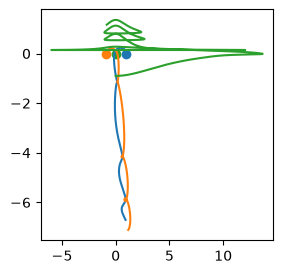

In [14]:
#y0 = np.random.random( (2,2,2) ) - 0.5
manyplanets(y0, tmax=4.5 )
plt.savefig('twoplanets-demo.pdf',dpi=300)
DATA=np.hstack((sol.t.reshape((numTimes,1)),sol.y.T))
np.savetxt('planets.txt',DATA,fmt='%.4e',delimeter='\t')

In [11]:
abc=np.zeros(3)
print(abc.shape)

(3,)
